In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

In [4]:
# 1. Read dataset
df = pd.read_csv("sales_data_sample.csv", encoding='latin1')
print(df.head())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [11]:
# 2. Select numerical features
X = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES']]

# 3. Handle missing values
X = X.fillna(X.mean())

# 4. Normalize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



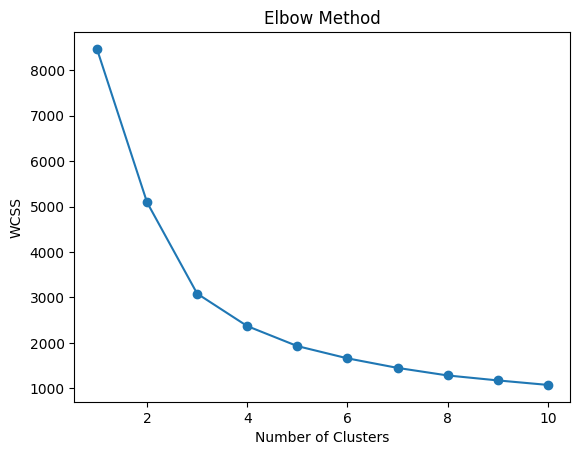

In [12]:
# 5. Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i, random_state=42, n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot elbow graph
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [13]:
# 6. K-Means Clustering
kmeans = KMeans(
    n_clusters=3, random_state=42, n_init=10
)

df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("\nK-Means Clusters:")
print(df['KMeans_Cluster'].value_counts())


K-Means Clusters:
KMeans_Cluster
2    1035
1     907
0     881
Name: count, dtype: int64


In [14]:
# 7. Hierarchical Clustering
hc = AgglomerativeClustering(n_clusters=3)

df['Hierarchical_Cluster'] = hc.fit_predict(X_scaled)

print("\nHierarchical Clusters:")
print(df['Hierarchical_Cluster'].value_counts())

# 8. Display results
print(df[['SALES', 'KMeans_Cluster',
          'Hierarchical_Cluster']].head())



Hierarchical Clusters:
Hierarchical_Cluster
2    1124
0    1014
1     685
Name: count, dtype: int64
     SALES  KMeans_Cluster  Hierarchical_Cluster
0  2871.00               2                     2
1  2765.90               2                     2
2  3884.34               1                     1
3  3746.70               1                     0
4  5205.27               1                     1
